# Phase 5 and 5b: do archetypes help the matchup answer?

Reads `reports/p4/`, `reports/p5/` and `reports/p5b/` only (nothing is recomputed). Differences are paired log-loss
differences, **negative = the first model is better**. Phase 5 numbers are the one pre-registered test-season result (D-048, D-049).
Phase 5b numbers are 2024 validation and exploratory (D-052, D-053, D-055); anything from `second_look.json` carries its label (D-054).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cricmind import config

P4, P5, P5B = (config.REPORTS / d for d in ("p4", "p5", "p5b"))


def load(path):
    return json.loads(path.read_text()) if path.exists() else None


head, valfit = load(P5 / "headline.json"), load(P5 / "val_fit.json")
cl4, roles = load(P4 / "clusters.json"), load(P5B / "role_clusters.json")
chain, look = load(P5B / "chain_val.json"), load(P5B / "second_look.json")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def forest(ax, paired, keys, title):
    """Point and 95% CI of each paired difference; the line at 0 is 'no difference'."""
    rows = [paired[k] for k in keys]
    y = np.arange(len(keys))[::-1]
    ax.hlines(y, [r["lo"] for r in rows], [r["hi"] for r in rows], color="tab:gray", lw=2)
    ax.plot([r["value"] for r in rows], y, "o", color="tab:blue")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([k.replace("__minus__", " - ") for k in keys], fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("log-loss difference (negative favours the first model)")

## 1. Phase 5 headline (test seasons, labelled-pair rows decide, D-049)
Both archetype tables beat the phase baseline, and the stats table beats the embedding table. The individual-player models are about ten times further away than the tables are from the baseline: archetypes are a lossy summary of players.

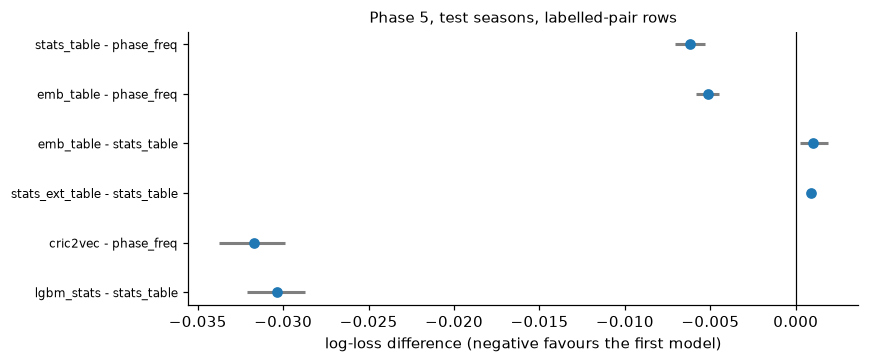

In [2]:
keys = [
    "stats_table__minus__phase_freq",
    "emb_table__minus__phase_freq",
    "emb_table__minus__stats_table",
    "stats_ext_table__minus__stats_table",
    "cric2vec__minus__phase_freq",
    "lgbm_stats__minus__stats_table",
]
fig, ax = plt.subplots(figsize=(8, 3.4))
forest(ax, head["paired"]["labelled_pairs"], keys, "Phase 5, test seasons, labelled-pair rows")
plt.tight_layout()

## 2. Coverage: how many rows an archetype table can serve
Only rows where both players have a label get a table prediction; the rest fall back to the phase baseline. The nearest-centre extension (D-050) roughly doubles coverage.

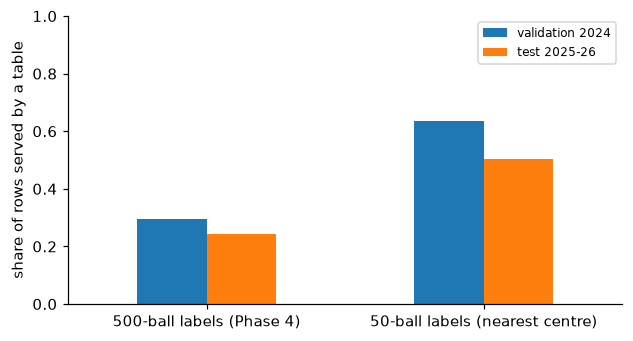

In [3]:
val_share = [valfit["arms"][a]["val_served_share"] for a in ("stats", "stats_ext")]
share = pd.DataFrame(
    {
        "validation 2024": val_share,
        "test 2025-26": [head["labelled_pair_share"], head["ext_labelled_pair_share"]],
    },
    index=["500-ball labels (Phase 4)", "50-ball labels (nearest centre)"],
)
ax = share.plot.bar(rot=0, figsize=(6.5, 3.4), ylim=(0, 1))
ax.set_ylabel("share of rows served by a table")
ax.legend(fontsize=8)

## 3. Do usage features make the groups stable? (Phase 4 outcome-rate clusters vs Phase 5b role clusters)
Bootstrap ARI against k at each clustering's chosen floor and PCA setting. The dashed line is the 0.6 gate. Batters reach it with usage features; bowlers get closer but stop just short.

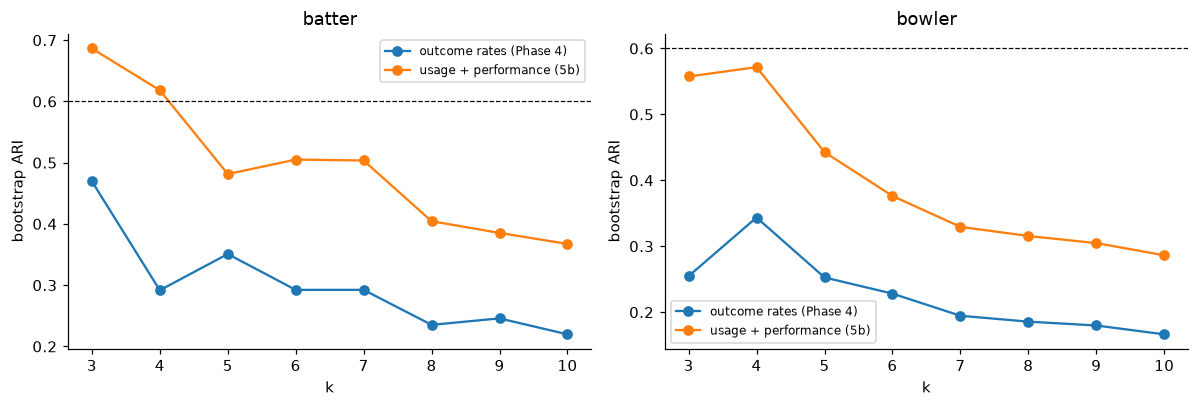

In [4]:
def table_of(cell):
    return cell["tables"][str(cell["min_balls"]) + "_" + ("pca" if cell["pca"] else "raw")]


fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, role in zip(ax, ["batter", "bowler"], strict=True):
    for name, cell in (
        ("outcome rates (Phase 4)", cl4["cells"]["stats_" + role]),
        ("usage + performance (5b)", roles["cells"][role]),
    ):
        t = table_of(cell)
        a.plot([r["k"] for r in t], [r["boot_ari_mean"] for r in t], marker="o", label=name)
    a.axhline(0.6, ls="--", color="k", lw=0.8)
    a.set_title(role)
    a.set_xlabel("k")
    a.set_ylabel("bootstrap ARI")
    a.legend(fontsize=8)
plt.tight_layout()

## 4. What the role clusters are
Per cluster: its size and the three features furthest from the population (z-score) with their raw means. Name only the stable role (batters) and only as 'tends to be' (D-047 naming rule).

In [5]:
rows = [
    {"role": role, "cluster": p["cluster"], "size": p["size"], "feature": f, "z": v["z"], "mean": v["mean"]}
    for role, cell in roles["cells"].items()
    for p in cell["profiles"]
    for f, v in p["top"].items()
]
pd.DataFrame(rows).round(3)

,role,cluster,size,feature,z,mean
0,batter,0,507,strike_rate_powerplay,-0.688,106.904
1,batter,0,507,share_middle,0.648,0.536
2,batter,0,507,boundary_pct_powerplay,-0.642,15.720
3,batter,1,427,share_powerplay,0.902,0.490
4,batter,1,427,entry_over,-0.849,3.413
5,batter,1,427,entry_wickets,-0.839,1.223
6,batter,2,205,share_death,1.725,0.471
7,batter,2,205,entry_wickets,1.598,4.457
8,batter,2,205,entry_over,1.567,12.229
9,bowler,0,226,share_middle,-0.901,0.261


## 4b. Is there more structure now? Silhouette by k
Stability (section 3) can rise while the groups stay blurry. Silhouette says how separated the bins are: under 0.25 means no substantial structure. A higher bootstrap ARI with a silhouette still near 0.2 would mean the usage features made the cut reproducible, not that cricket has natural batter types.

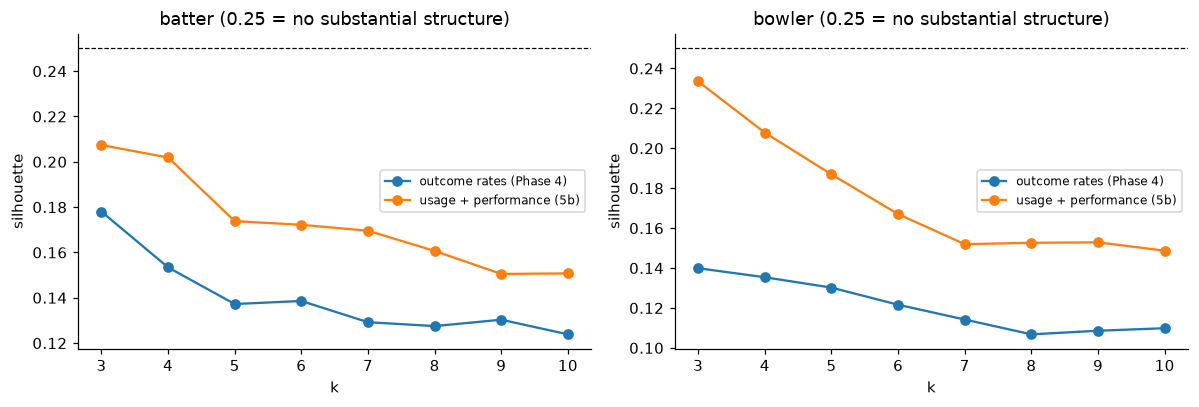

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, role in zip(ax, ["batter", "bowler"], strict=True):
    for name, cell in (
        ("outcome rates (Phase 4)", cl4["cells"]["stats_" + role]),
        ("usage + performance (5b)", roles["cells"][role]),
    ):
        t = table_of(cell)
        a.plot([r["k"] for r in t], [r["silhouette"] for r in t], marker="o", label=name)
    a.axhline(0.25, ls="--", color="k", lw=0.8)
    a.set_title(role + " (0.25 = no substantial structure)")
    a.set_xlabel("k")
    a.set_ylabel("silhouette")
    a.legend(fontsize=8)
plt.tight_layout()

## 4c. The role players on the map
First two principal components of the standardised role vector, coloured by bin (same recipe as the Phase 4 scatter, so the two can be compared). In Phase 4 the colours tiled one cloud with no gaps. The question here is whether the batter bins now sit in visibly separate regions, which is what a bootstrap ARI of 0.69 would predict.

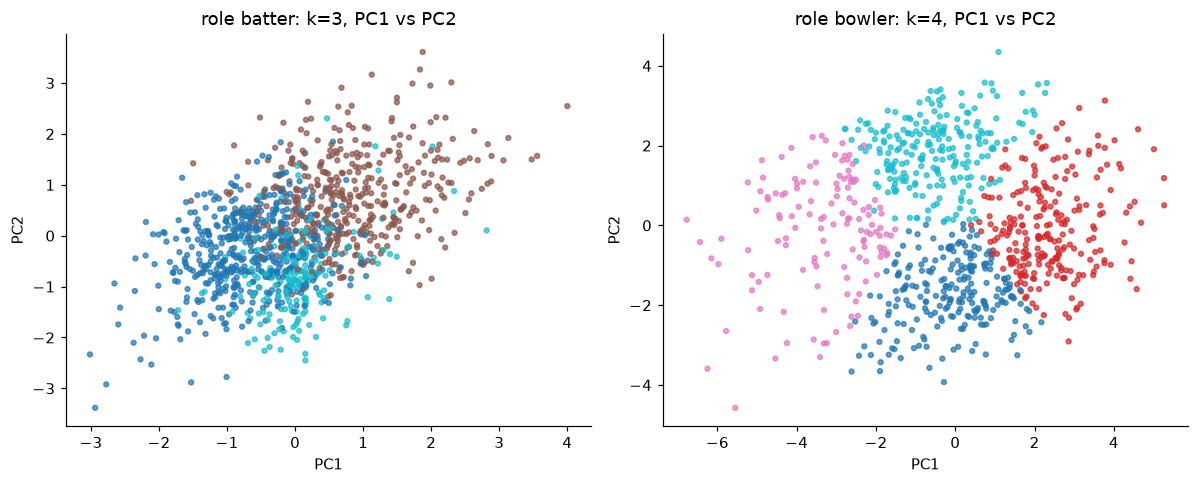

In [7]:
import joblib

from cricmind.archetypes import vectors as vec
from cricmind.archetypes.roles import role_vectors

ART = config.ARTIFACTS / "p4"
train, _ = vec.load_train()  # train rows only; takes a moment
arch = pd.read_parquet(ART / "archetypes_role.parquet")
feats = {}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, role in zip(ax, ["batter", "bowler"], strict=True):
    lab = arch[arch["role"] == role]
    X = role_vectors(train, role, pd.Index(lab["player_id"]))
    feats[role] = (X, lab["label"].to_numpy())
    model = joblib.load(ART / f"kmeans_role_{role}.joblib")
    Z = model[:-1].transform(X.to_numpy())  # the clustering's own space (scaler, and PCA when chosen)
    a.scatter(Z[:, 0], Z[:, 1], c=lab["label"], cmap="tab10", s=10, alpha=0.7)
    a.set_title(f"role {role}: k={roles['cells'][role]['k']}, PC1 vs PC2")
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 4d. What each role bin is (z-score of every feature against all eligible players)
Red = above the population, blue = below. Columns are performance (strike rate, dot %, boundary % per phase), usage (`share_*` of balls per phase) and, for batters, entry (`entry_over`, `entry_wickets`). A bin that is strongly red on `share_powerplay` and low on `entry_over` is an opener-type bin; a bin high on `share_death` is a finisher-type bin. Naming rule (D-047, D-052): name a bin only if its clustering is stable (batters yes, bowlers no) and only as 'tends to be'; clusterwise Jaccard has not been computed for the role clusters, so treat even the batter names as provisional.

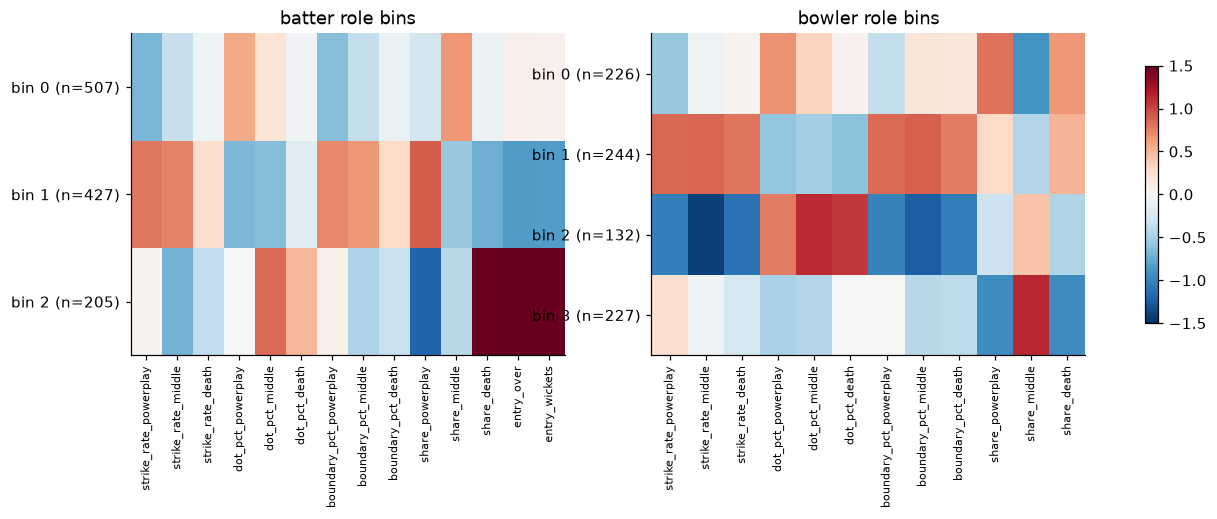

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a, role in zip(ax, ["batter", "bowler"], strict=True):
    X, lab = feats[role]
    z = (X - X.mean()) / X.std(ddof=0)
    prof = z.groupby(lab).mean()
    im = a.imshow(prof.to_numpy(), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    a.set_xticks(range(prof.shape[1]), prof.columns, rotation=90, fontsize=7)
    sizes = np.bincount(lab)
    a.set_yticks(range(len(prof)), [f"bin {i} (n={sizes[i]})" for i in prof.index])
    a.set_title(f"{role} role bins")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## 4e. All four clusterings side by side, with bin centres
Top row: outcome-rate bins (Phase 4). Bottom row: role bins (5b). Each panel runs its own 2-D PCA of the standardised vectors, so compare the shape of the cloud and how cleanly the colours separate, not the axis values. Batters sit on the left; the role batter panel is the one with the stable clustering (ARI 0.69).

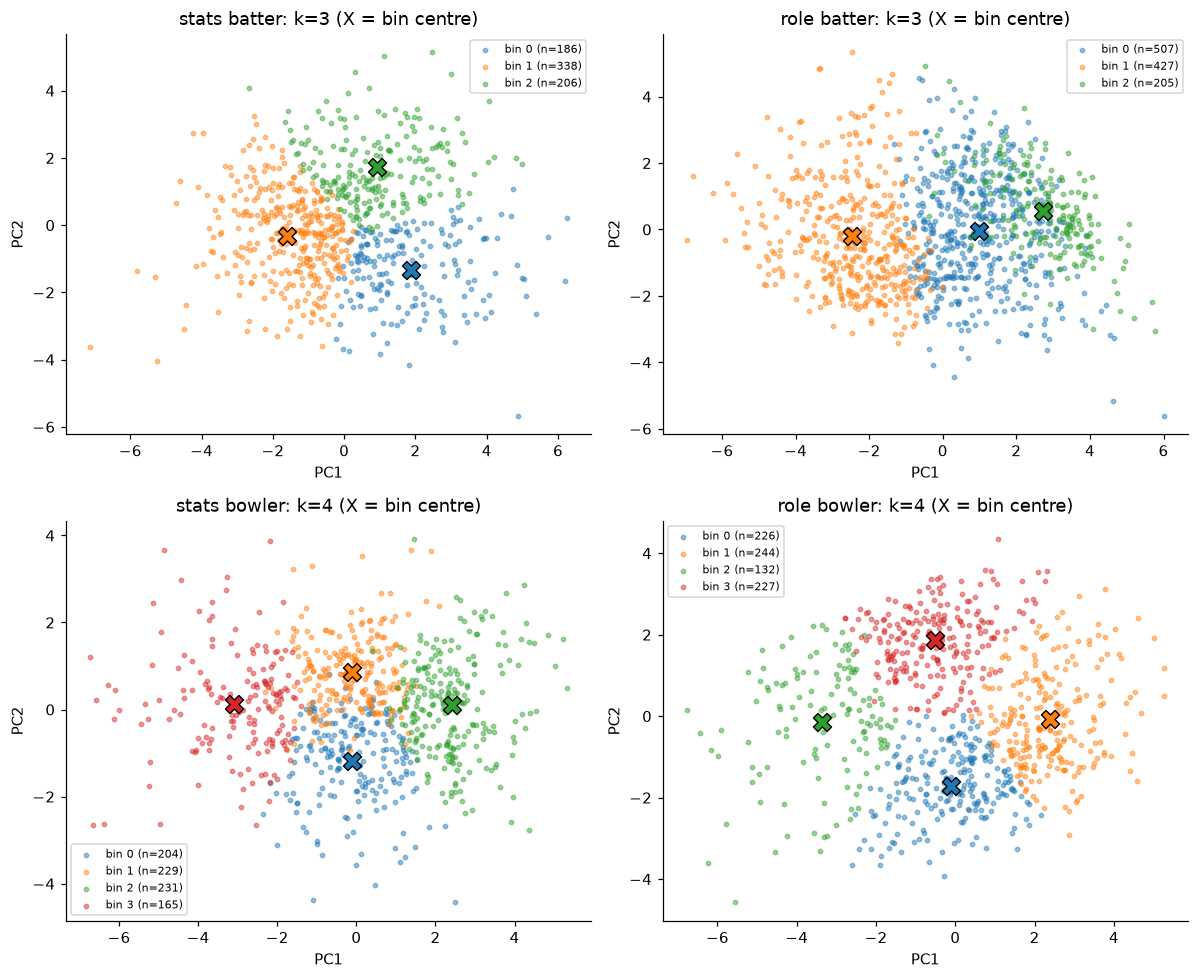

In [12]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

stats_arch = pd.read_parquet(ART / "archetypes_stats.parquet")
stats_arch = stats_arch[stats_arch["method"] == "kmeans"]
views = {}
for role in ("batter", "bowler"):
    lab = stats_arch[stats_arch["role"] == role]
    stats_x = vec.stats_vectors(train, role, pd.Index(lab["player_id"])).to_numpy()
    views[("stats", role)] = (stats_x, lab["label"].to_numpy())
    X, labels = feats[role]
    views[("role", role)] = (X.to_numpy(), labels)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for a, ((rep, role), (X, lab)) in zip(axes.ravel(), views.items(), strict=True):
    Z = PCA(2, random_state=config.SEED).fit_transform(StandardScaler().fit_transform(X))
    for i, c in enumerate(np.unique(lab)):
        pts = Z[lab == c]
        a.scatter(pts[:, 0], pts[:, 1], s=8, alpha=0.45, color=f"C{i}", label=f"bin {c} (n={len(pts)})")
        a.scatter(*pts.mean(axis=0), marker="X", s=140, color=f"C{i}", edgecolor="k", linewidth=0.9)
    a.set_title(f"{rep} {role}: k={len(np.unique(lab))} (X = bin centre)")
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 4f. The same bins on two features you can read
PCA axes are blends of all features, so they are hard to name. Here the axes are single features: for batters, the average over they first face a ball (x) against their share of balls faced at the death (y); for bowlers, their share of balls in the powerplay (x) against the death (y). If a bin sits in its own corner, that corner is what the bin is.

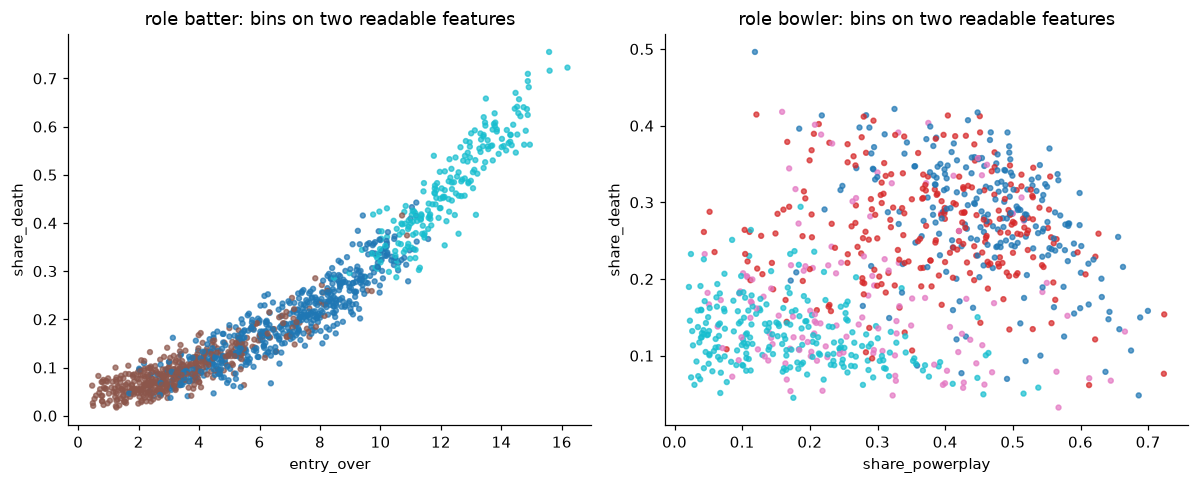

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
views2 = [("batter", "entry_over", "share_death"), ("bowler", "share_powerplay", "share_death")]
for a, (role, x, y) in zip(ax, views2, strict=True):
    X, lab = feats[role]
    a.scatter(X[x], X[y], c=lab, cmap="tab10", s=10, alpha=0.7)
    a.set_xlabel(x)
    a.set_ylabel(y)
    a.set_title(f"role {role}: bins on two readable features")
plt.tight_layout()
plt.show()

## 5. The leak that D-055 fixed, and the hierarchical chain on 2024
Left: how much each level lowers the **tuning-year (2023)** loss. Right: the paired val differences that decide the archetype question (D-053(5)). If the first panel shows the archetype cell helping a lot and the right panel shows nothing, the tuning step is leaking; this notebook reads the leak-free run (`leak_free_tuning` = true).

leak_free_tuning: True


{'min_gain': 0.002,
 'archetype_level_kept': False,
 'role_beats_stats': False,
 'role_clusters_stable': {'batter': True, 'bowler': False}}

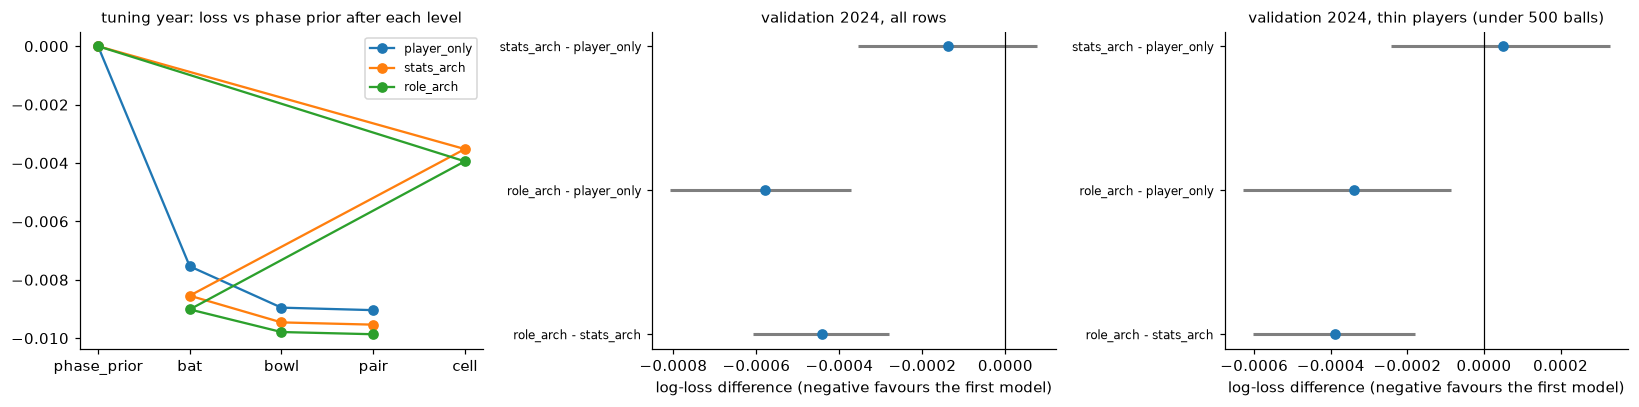

In [9]:
print("leak_free_tuning:", chain.get("leak_free_tuning", False))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for name, v in chain["variants"].items():
    steps = v["steps"]
    drop = [s["tune_log_loss"] - steps[0]["tune_log_loss"] for s in steps]
    ax[0].plot([s["level"] for s in steps], drop, marker="o", label=name)
ax[0].set_title("tuning year: loss vs phase prior after each level", fontsize=10)
ax[0].legend(fontsize=8)
keys = ["stats_arch__minus__player_only", "role_arch__minus__player_only", "role_arch__minus__stats_arch"]
forest(ax[1], chain["paired"]["all"], keys, "validation 2024, all rows")
forest(ax[2], chain["paired"]["thin"], keys, "validation 2024, thin players (under 500 balls)")
plt.tight_layout()
chain["decisions"]

## 6. How much of the available gain does each model capture? (validation 2024)
Log-loss improvement over the phase baseline. Game state (score, wickets, venue) is in LightGBM and cric2vec but not in the chain or the tables, which is why they win so clearly.

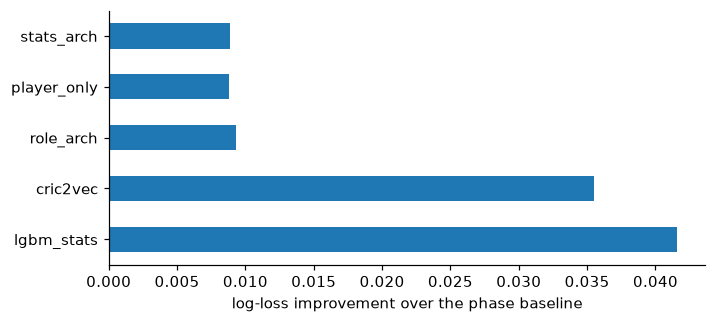

In [10]:
ll = {arm: v["value"] for arm, v in chain["slices"]["all"]["log_loss"].items()}
arms = ["stats_arch", "player_only", "role_arch", "cric2vec", "lgbm_stats"]
gain = pd.Series({a: ll["phase_freq"] - ll[a] for a in arms})
ax = gain.plot.barh(figsize=(7, 3), color="tab:blue")
ax.set_xlabel("log-loss improvement over the phase baseline")
ax.invert_yaxis()

## 7. Second look at the spent test seasons (only if it has been run)
D-054: exploratory, not a held-out claim. Same pre-registered variants and frozen `s`; agreement with the validation decisions is the only thing it adds.

SECOND LOOK at spent test seasons (D-054): exploratory, not a held-out claim
{'archetype_level_kept': False, 'role_beats_stats': False} agrees with val: {'archetype_level_kept': True, 'role_beats_stats': True}


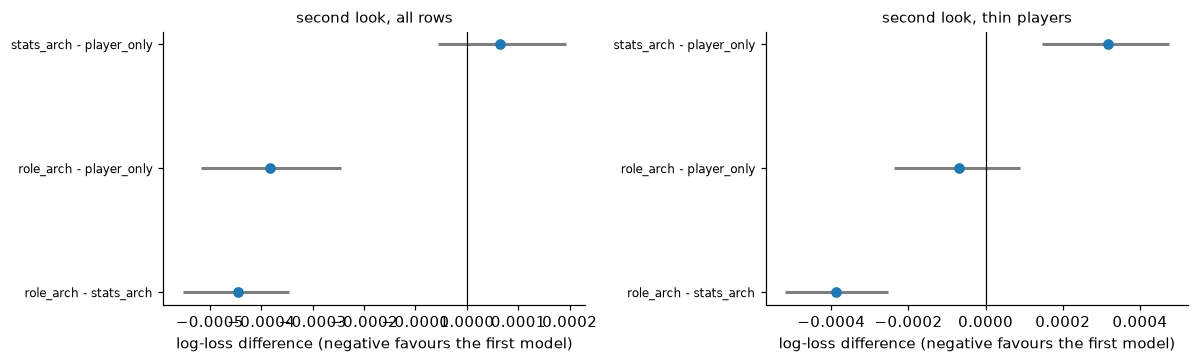

In [11]:
if look is None:
    print("second_look.json not written yet")
else:
    print(look["label"])
    keys = ["stats_arch__minus__player_only", "role_arch__minus__player_only", "role_arch__minus__stats_arch"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    forest(ax[0], look["paired"]["all"], keys, "second look, all rows")
    forest(ax[1], look["paired"]["thin"], keys, "second look, thin players")
    plt.tight_layout()
    print(look["decisions"], "agrees with val:", look["agrees_with_val"])